






















































































































































































































































































































































































































































































































































































































































































































































































































































































































































# **1. Data Normalization**

https://scikit-learn.org/stable/modules/preprocessing.html

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data3.csv')
data

**Decimals Scalling**

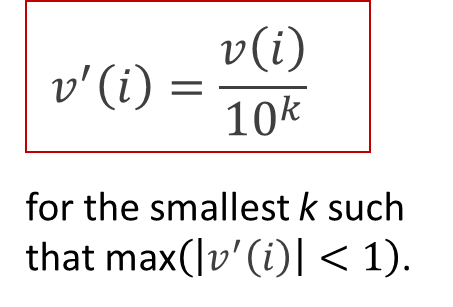

In [ ]:
data["Age"].max()
data["Age"] = data["Age"]/10**2

In [ ]:
data

**Min-Max Scaling**

*1. Manual*

In [ ]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data3.csv')
data

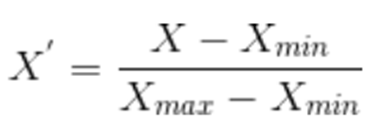

In [ ]:
data["Age"]=(data["Age"]-data["Age"].min())/(data["Age"].max()-data["Age"].min())

In [ ]:
data["Age"] = data["Age"].round(3)

In [ ]:
data

*2. Library*

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data

In [ ]:
data["Age"] = MinMaxScaler().fit_transform(data[["Age"]])

In [ ]:
data

**Z-score Standardization**

In [ ]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data3.csv')
data

*1. Manual*

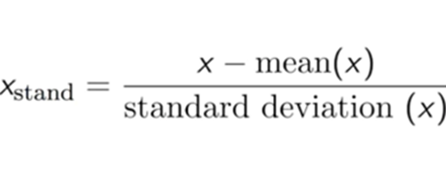

In [ ]:
data["Age"] = (data["Age"]-data["Age"].mean())/data["Age"].std()

In [ ]:
data["Age"] = data["Age"].round(3)

In [ ]:
data

*2. Library*

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
data["Age"] = StandardScaler().fit_transform(data[['Age']])

In [ ]:
data

**Robust Scaling**

In [ ]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data3.csv')
data

*1. Manual*

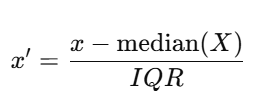

In [ ]:
q1 = data['Age'].quantile(0.25)
q3 = data['Age'].quantile(0.75)
iqr = q3 - q1

In [ ]:
data["Age"] = (data["Age"]-data["Age"].median())/iqr

In [ ]:
data

*2. Library*

In [ ]:
from sklearn.preprocessing import RobustScaler

In [ ]:
data["Age"] = RobustScaler().fit_transform(data[['Age']])

In [ ]:
data

# **2. Encoding**

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [ ]:
# Encoding Severity Levels (ordinal data)
severity = ['Low', 'Medium', 'High', 'Medium', 'Low']
data = pd.DataFrame({'Severity': severity})
data

In [ ]:
# Label Encoding
label_encoder = LabelEncoder()
data['Severity_encoded'] = label_encoder.fit_transform(data['Severity'])
data

# **3. Data Discretization**

| Metode              | Dasar Pembagian        | Lebar Interval | Jumlah Data per Bin |
| ------------------- | ---------------------- | -------------- | ------------------- |
| **Equal-Width**     | Nilai range (min–max)  | Sama           | Bisa tidak seimbang |
| **Equal-Frequency** | Jumlah data (quantile) | Bisa berbeda   | Sama (atau hampir)  |


In [ ]:
data = {'Temperature': [22.5, 25.1, 30.8, 33.2, 35.7, 27.6, 29.3, 24.8]}
data = pd.DataFrame(data)
data

Equal-Width

In [ ]:
# Membagi menjadi 3 interval dengan lebar yang sama
data['Temp_Bin'] = pd.cut(data['Temperature'], bins=3, labels=['Low', 'Medium', 'High'])
data

Equal-Frequency

In [ ]:
# Membagi menjadi 3 interval dengan jumlah data yang sama (equal frequency)
data['Temp_Quantile'] = pd.qcut(data['Temperature'], q=3, labels=['Low', 'Medium', 'High'])
data


# **4. Data Measurement and Aggregation**

In [ ]:
# data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data_awal_transformasi.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data_awal_transformasi.csv')

In [ ]:
data.head()

*Different Unit of Measurement*

In [ ]:
data['Tinggi'] = data['Tinggi'] * 100
data

*Different Level of Aggregation*

In [ ]:
data_num = data.iloc[:,2:]
data_num.head()

In [ ]:
data_agg = data_num.groupby('Bulan').mean()
data_agg

# **Attribute Construction**

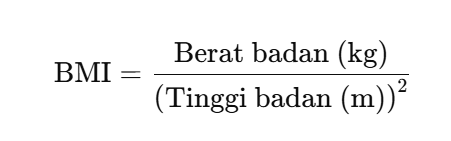

In [ ]:
data['BMI'] = data['Berat']/(data['Tinggi'])**2

In [ ]:
data.head()

# **Data Smoothing**

In [ ]:
data_smooth = data.copy()

In [ ]:
data_smooth.head()

In [ ]:
# Moving Average (window 3)
data_smooth['Berat_MA'] = data_smooth['Berat'].rolling(window=3).mean()

# Exponential Smoothing (alpha 0.3)
data_smooth['Tinggi_ES'] = data_smooth['Tinggi'].ewm(alpha=0.3).mean()

In [ ]:
data_smooth.head()

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data/data3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/brina948/data-mining/refs/heads/main/datasets/data3.csv')
data

In [ ]:
data.head()